# 02 · Follow the Smart Consensus

Instead of one wallet, copy a whole **smart-money cohort** for a category. We
take the top smart wallets from the keyless leaderboard, backtest each, and
blend them into one equal-weight cohort equity curve — then compare it to a
flat (do-nothing) baseline.

> ⚠️ **Informational only — NOT financial advice.** Past performance does not
> predict future results.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

from utils.oc_backtest import leaderboard, blend_cohort

Choose a category and cohort size. The leaderboard call is keyless;
`filter="smart"` applies OrcaLayer's farmer/hedger exclusion.

In [2]:
CATEGORY = "Crypto"
N = 8

cohort = leaderboard(category=CATEGORY, filter="smart", limit=N)
print(f"{len(cohort)} smart wallets in {CATEGORY}:")
for w in cohort:
    print(f"  {w.get('name') or w['wallet'][:12]:20s}  ${w.get('total_pnl', 0):>14,.0f}  WR {w.get('win_rate')}%")

8 smart wallets in Crypto:
  coinman2              $     1,142,831  WR 55.6%
  Squiggly-Menopause    $       938,164  WR 58.2%
  stonksgoup            $       921,624  WR 59.1%
  Respectful-Clan       $       918,596  WR 65.1%
  kingofcoinflips       $       857,125  WR 54.4%
  HaileyWelch           $       820,648  WR 55.3%
  Attentive-Silica      $       727,451  WR 63.9%
  Circus-995            $       698,438  WR 56.4%


Backtest every wallet and blend them. `blend_cohort` sums P&L by resolution
time across the cohort (an equal-weight "copy them all" portfolio) and paces
the loop under the 300-requests/min rate limit.

In [3]:
curve, summaries = blend_cohort(cohort, limit=500)
curve["date"] = pd.to_datetime(curve["last_trade_ts"], unit="s")
pd.DataFrame(summaries)[["name", "wallet", "resolved", "win_rate", "total_pnl"]]

,name,wallet,resolved,win_rate,total_pnl
0,coinman2,0x55be7aa03ecfbe37aa5460db791205f7ac9ddca3,500,56.2,79364.54
1,Squiggly-Menopause,0xebf79787ab928c803cbef6fa8e0abe42b9e1da78,500,52.0,110719.86
2,stonksgoup,0x4a38e6e0330c2463fb5ac2188a620634039abfe8,500,51.8,2652.97
3,Respectful-Clan,0x6e1d5040d0ac73709b0621f620d2a60b80d2d0fa,498,51.6,3543.61
4,kingofcoinflips,0xe9c6312464b52aa3eff13d822b003282075995c9,500,53.0,-122703.43
5,HaileyWelch,0x80cd8310aa624521e9e1b2b53b568cafb0ef0273,500,53.4,-20166.67
6,Attentive-Silica,0xde17f7144fbd0eddb2679132c10ff5e74b120988,500,51.2,253679.43
7,Circus-995,0x28065f1b88027422274fb33e1e22bf3dad5736e7,464,49.6,-225585.67


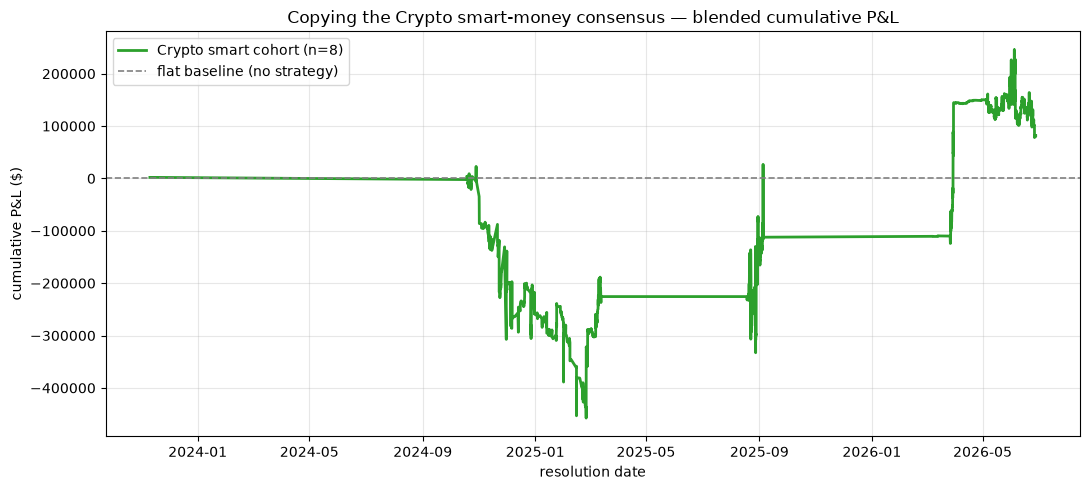

In [4]:
plt.figure(figsize=(11, 5))
plt.plot(curve["date"], curve["equity"], lw=2, color="#2ca02c",
         label=f"{CATEGORY} smart cohort (n={len(cohort)})")
plt.axhline(0, color="grey", lw=1.2, ls="--", label="flat baseline (no strategy)")
plt.title(f"Copying the {CATEGORY} smart-money consensus — blended cumulative P&L")
plt.xlabel("resolution date")
plt.ylabel("cumulative P&L ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Headline numbers for the blended cohort.

In [5]:
final_pnl = float(curve["equity"].iloc[-1]) if not curve.empty else 0.0
print(f"Cohort final P&L:   ${final_pnl:,.0f}")
print(f"Resolved positions: {len(curve)}")
print(f"Wallets blended:    {len(cohort)}")

Cohort final P&L:   $81,505
Resolved positions: 3373
Wallets blended:    8


Blending several smart wallets smooths out any single wallet's luck — it
approximates "follow the consensus" rather than betting on one trader. It is
still a backward-looking measurement on resolved markets, **not** a forward
prediction.

> ⚠️ Informational only — not financial advice.